In [ ]:
# IBM HR Attrition - Complete Project for Internship
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix




In [ ]:
# 1. Load Data
df = pd.read_csv('/content/archive (3).zip')
print(df.shape) # (1470, 35)
print(df['Attrition'].value_counts())

(1470, 35)
Attrition
No     1233
Yes     237
Name: count, dtype: int64


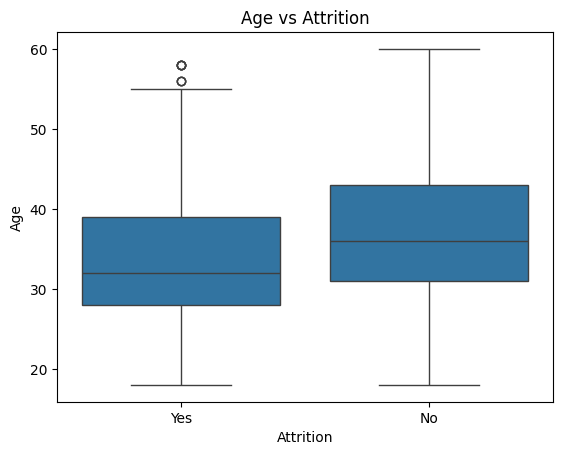

In [ ]:
# 2. EDA - Key Insights
# Age vs Attrition
sns.boxplot(x='Attrition', y='Age', data=df)
plt.title('Age vs Attrition')
plt.show()

In [ ]:
# Department wise Attrition %
pd.crosstab(df['Department'], df['Attrition'], normalize='index')*100


Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


In [ ]:
# 3. Data Cleaning & Encoding
df_processed = df.copy()
df_processed['Attrition'] = df_processed['Attrition'].map({'Yes':1, 'No':0})
# One-hot for categoricals
df_processed = pd.get_dummies(df_processed, drop_first=True)

In [ ]:
# 4. Model Training
X = df_processed.drop('Attrition', axis=1)
y = df_processed['Attrition']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
# 5. Evaluation
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.99      0.91       247
           1       0.50      0.06      0.11        47

    accuracy                           0.84       294
   macro avg       0.67      0.53      0.51       294
weighted avg       0.79      0.84      0.78       294

[[244   3]
 [ 44   3]]


              Feature  Importance
11      MonthlyIncome    0.064797
0                 Age    0.055813
19  TotalWorkingYears    0.054487
1           DailyRate    0.049857
5      EmployeeNumber    0.045983
46       OverTime_Yes    0.045329
2    DistanceFromHome    0.043468
12        MonthlyRate    0.043059
7          HourlyRate    0.041870
22     YearsAtCompany    0.040619


<Axes: xlabel='Importance', ylabel='Feature'>

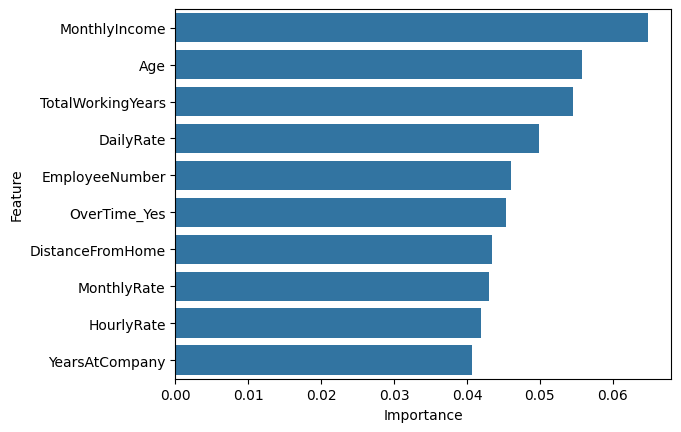

In [ ]:
# 6. Feature Importance - For Resume
importances = pd.DataFrame({'Feature': X.columns, 'Importance': model.feature_importances_}).sort_values('Importance', ascending=False).head(10)
print(importances)
sns.barplot(x='Importance', y='Feature', data=importances)

In [ ]:
# 7. ROI Calculation - Ye sabse important hai interview ke liye
# Assume: 1 employee ko replace karne ka cost = 1.5 * Annual Salary (~ $15k avg)
# Model agar 50 logo ko rok le to kitna paisa bachega
prevented_attrition = 50
avg_replacement_cost = 15000
total_saving = prevented_attrition * avg_replacement_cost
print(f"Estimated Annual Saving if model prevents 50 attritions: ${total_saving}")

Estimated Annual Saving if model prevents 50 attritions: $750000
